# Число узлов в каждом эксперименте и каждом пайплайне

In [6]:
import sys
import os
import json

sys.path.append('./../')

In [7]:
import numpy as np
import pandas as pd
from dotenv import load_dotenv

from eval.self_repeatness import count_self_repeating_part
from eval.variarity import count_fields_variance
from eval.md_classes import MDField, DataStep

load_dotenv()

True

In [8]:
QUERIES_CNT = 16
RUNS = 8

## Вспомогательные функции

In [9]:
def count_nodes_per_run_m2(df: pd.DataFrame, q_id: int, runs_cnt: int):
    nodes_cnt_per_run = []

    for r in range(runs_cnt):
        loc_df = df.loc[(df['query_id'] == q_id) & (df['run_id'] == r)]
        nodes_set = set()
        
        for r_id, row in loc_df.iterrows():
            row_nodes = row['dag_step']
            row_nodes = set(row_nodes)
            nodes_set = nodes_set.union(row_nodes)

        nodes_cnt_per_run.append(len(nodes_set))

    return nodes_cnt_per_run

def count_nodes_per_run_m34(df: pd.DataFrame, q_id: int, runs_cnt: int):
    nodes_cnt_per_run = []

    for r in range(runs_cnt):
        loc_df = df.loc[(df['query_id'] == q_id) & (df['run_id'] == r)]
        nodes_set = set()
        
        for r_id, row in loc_df.iterrows():
            node_name = row['node_name']
            nodes_set.add(node_name)

        nodes_cnt_per_run.append(len(nodes_set))

    return nodes_cnt_per_run

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def plot_chart(
        means, 
        stds, 
        n_tasks, 
        n_setups, 
        task_labels,
        setup_labels,
    ):
    BAR_W    = 0.22
    GROUP_GAP = 0.05
    
    # Centre positions for each group
    x = np.arange(n_tasks) * (n_setups * BAR_W + GROUP_GAP + 0.1)
    
    # Offsets so bars are centred inside the group
    offsets = (np.arange(n_setups) - (n_setups - 1) / 2) * BAR_W
    
    COLORS  = ["#4C72B0", "#DD8452", "#55A868", "#FC0D54"]   # colorblind-friendly
    ECOLOR  = "black"
    CAPSIZE = 4
    
    fig, ax = plt.subplots(figsize=(18, 6))
    
    for s in range(n_setups):
        ax.bar(
            x + offsets[s],
            means[s],
            width=BAR_W,
            color=COLORS[s],
            alpha=0.85,
            label=setup_labels[s],
            yerr=stds[s],
            error_kw=dict(ecolor=ECOLOR, capsize=CAPSIZE, capthick=1.2, lw=1.2),
            zorder=3,
        )
    
    # ── 4. STYLING ────────────────────────────────────────────────────────────────
    
    ax.set_xticks(x)
    ax.set_xticklabels(task_labels, rotation=35, ha="right", fontsize=9)
    ax.set_ylabel("Field Count", fontsize=11)
    ax.set_xlabel("Task", fontsize=11)
    ax.set_title("Schema Field Count per Task & Experiment Setup\n(mean ± std, 8 runs each)",
                fontsize=13, pad=14)
    
    ax.yaxis.grid(True, linestyle="--", alpha=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    
    legend_patches = [
        mpatches.Patch(color=COLORS[s], label=setup_labels[s]) for s in range(n_setups)
    ]
    ax.legend(handles=legend_patches, frameon=False, fontsize=10)
    
    plt.tight_layout()
    plt.savefig("./nodes_per_task.png", dpi=300, bbox_inches="tight")
    plt.show()


# Визуализация результатов

In [15]:
md_tables = {
    'm2': './../data/md_generations/m2_synth_bio_mds.csv',
    'm3': './../data/md_generations/m3_synth_bio_mds/m3_synth_bio_mds.csv',
    'm4': './../data/md_generations/m4_synth_bio_mds/m4_synth_bio_mds.csv',
}

nodes_counter = {
    'm2': count_nodes_per_run_m2,
    'm3': count_nodes_per_run_m34,
    'm4': count_nodes_per_run_m34,
}

means = []
stds = []

for p_name, p_path in md_tables.items():
    df = pd.read_csv(p_path)

    new_means = []
    new_stds = []

    for q_id in range(QUERIES_CNT):
        fields_cnts = nodes_counter[p_name](df, q_id, RUNS)
        if q_id == 5:
            print(fields_cnts)
        new_means.append(np.mean(fields_cnts))
        new_stds.append(np.std(fields_cnts))
    
    means.append(new_means)
    stds.append(new_stds)

[23, 23, 22, 20, 22, 28, 22, 21]
[13, 13, 15, 17, 14, 13, 14, 13]
[29, 27, 39, 56, 47, 33, 36, 78]


## Визуализация

In [13]:
import json

task_labels = []
with open('./../queries/bio_queries.yaml', 'rt') as fio:
    d = json.load(fio)
    for el in d:
        task_labels.append(el['field_of_science'].split('/')[-1].strip())
task_labels

['Single-Cell Genomics',
 'Microbial Ecology',
 'Behavioral Neurobiology',
 'Plankton Ecology',
 'Infectious Disease Genomics',
 'Rhizosphere Ecology',
 'Molecular Gerontology',
 'Pollination Biology',
 'Mitochondrial Physiology',
 'Clinical Metagenomics',
 'Systems Neuroscience',
 'Ichthyology',
 'Molecular Biophysics',
 'Carbon Metabolism',
 'Cell Invasion Biology',
 'Cell Biology']

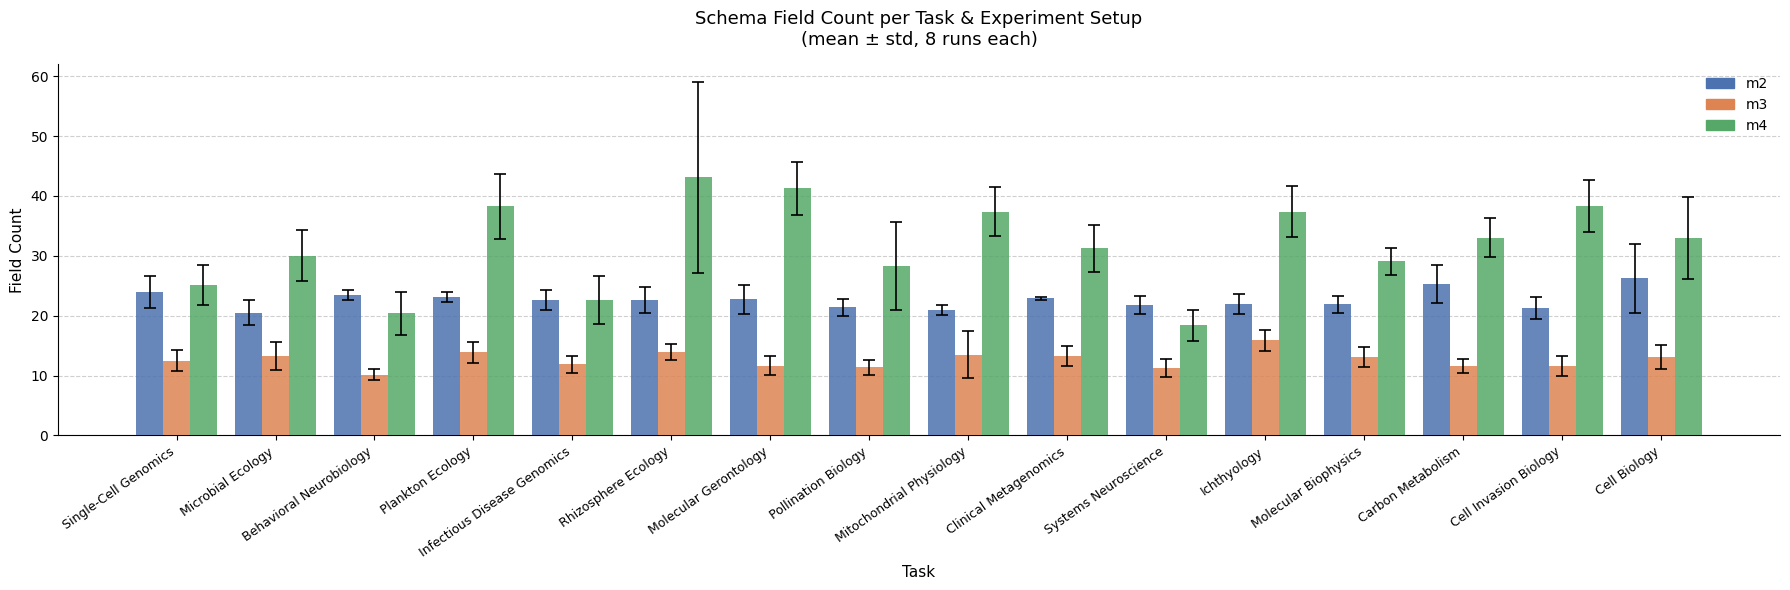

In [14]:
plot_chart(means, stds, QUERIES_CNT, len(md_tables), task_labels, list(md_tables.keys()))